# Yapay Uzay Nesnelerinin Sınıflandırma, Regresyon ve Kümeleme ile Analizi

Makine Öğrenmesi Dönem Ödevi

Bu çalışmada GCAT veri kümesindeki yapay uzay nesnelerinin fiziksel ve yörüngesel özelliklerini üç farklı makine öğrenmesi problemi için kullanacağım.

Sınıflandırmada nesne türlerini, regresyonda kütle tahminini, kümelemede ise benzer yörünge özelliklerine sahip nesne gruplarını inceleyeceğim.

## 1. Veri kümesi ve çalışma ortamı

GCAT (General Catalog of Artificial Space Objects), yapay uzay nesnelerine ilişkin fiziksel ve yörüngesel bilgiler içeren bir katalogdur. Çalışmada 9 Kasım 2026 tarihli veri sürümünü kullanacağım.

**Kaynak:** https://planet4589.org/space/gcat/

In [65]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

drive.mount("/content/drive")

DATA_PATH = Path("/content/drive/MyDrive/satcat.tsv")
SEED = 42

print("Dosya bulundu:", DATA_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dosya bulundu: True


## 2. Verinin okunması

GCAT veri dosyasını Pandas ile okuyacağım. Dosyanın ikinci satırındaki güncelleme bilgisini atlayarak veri boyutunu ve ilk kayıtları inceleyeceğim.

In [66]:
df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    skiprows=[1],
    dtype=str,
    low_memory=False
)

df.columns = df.columns.str.lstrip("#").str.strip()

print("Gözlem sayısı:", df.shape[0])
print("Değişken sayısı:", df.shape[1])

display(df.head())

Gözlem sayısı: 69999
Değişken sayısı: 42


,JCAT,Satcat,Launch_Tag,Piece,Type,Name,PLName,LDate,Parent,SDate,...,ODate,Perigee,PF,Apogee,AF,Inc,IF,OpOrbit,OQUAL,AltNames
0,S00001,00001,1957 ALP,1957 ALP 1,R2,8K71PS No. M1-10 Stage 2,8K71A M1-10 (M1-1PS),1957 Oct 4,-,1957 Oct 4 1933,...,1957 Oct 4,214,,938,,65.10,,LLEO/I,-,-
1,S00002,00002,1957 ALP,1957 ALP 2,P,1-y ISZ,PS-1,1957 Oct 4,S00001,1957 Oct 4 1933,...,1957 Oct 4,214,,938,,65.10,,LLEO/I,-,":RE,:RC"
2,S00003,00003,1957 BET,1957 BET 1,P A,2-y ISZ,PS-2,1957 Nov 3,A00002,1957 Nov 3 0235,...,1957 Nov 3,211,,1659,,65.33,,LEO/I,-,":RE,:RC"
3,S00004,00004,1958 ALP,1958 ALP,P A,Explorer I,Explorer 1,1958 Feb 1,A00004,1958 Feb 1 0355,...,1958 Feb 1,359,,2542,,33.18,,LEO/I,-,":UA,:UB,DEAL I:IA"
4,S00005,00005,1958 BET,1958 BET 2,P,Vanguard I,Vanguard Test Satellite H,1958 Mar 17,S00016,1958 Mar 17 1224,...,1959 May 23,657,,3935,,34.25,,MEO,-,":UA,:VA"


## 3. Veri kümesinin incelenmesi

Veri kümesindeki değişkenleri, eksik değerleri ve tekrar eden kayıtları inceleyerek veri kalitesini değerlendireceğim. Bu aşamada herhangi bir veri silmeden önce eksikliklerin dağılımını belirleyeceğim.

In [67]:
print("Veri boyutu:", df.shape)
print("Tekrar eden satır sayısı:", df.duplicated().sum())

df_clean = df.replace(r"^\s*$|^\s*[-?]\s*$", np.nan, regex=True)

missing = pd.DataFrame({
    "Eksik Sayısı": df_clean.isna().sum(),
    "Eksik Oranı (%)": (df_clean.isna().mean() * 100).round(2)
})

display(missing.sort_values("Eksik Oranı (%)", ascending=False).head(15))

Veri boyutu: (69999, 42)
Tekrar eden satır sayısı: 0


/tmp/ipykernel_4553/1363289415.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean = df.replace(r"^\s*$|^\s*[-?]\s*$", np.nan, regex=True)


,Eksik Sayısı,Eksik Oranı (%)
TotFlag,69999,100.00
IF,69999,100.00
LFlag,69999,100.00
DFlag,69999,100.00
SpanFlag,69999,100.00
PF,69999,100.00
AF,69999,100.00
MassFlag,69999,100.00
DryFlag,69999,100.00
OQUAL,69636,99.48


## 4. Değişkenlerin incelenmesi

Sınıflandırma için nesne türünü (`Type`), regresyon için kütleyi (`Mass`) hedef değişken olarak değerlendireceğim. Kümeleme için ise yörünge özelliklerinden yararlanmayı planlıyorum.

In [68]:
columns = [
    "Type", "Mass", "DryMass", "TotMass",
    "Length", "Diameter", "Span",
    "Perigee", "Apogee", "Inc"
]

display(df_clean[columns].head())

print("Nesne türleri:")
display(df_clean["Type"].value_counts().head(15))

mass = pd.to_numeric(df_clean["Mass"], errors="coerce")

print("Geçerli kütle değeri:", mass.notna().sum())
print("Pozitif kütle değeri:", (mass > 0).sum())

,Type,Mass,DryMass,TotMass,Length,Diameter,Span,Perigee,Apogee,Inc
0,R2,7790,7790,7800,28.0,2.6,28.0,214,938,65.10
1,P,84,84,84,0.6,0.6,2.9,214,938,65.10
2,P A,508,508,8298,2.0,1.0,2.0,211,1659,65.33
3,P A,8,8,14,0.8,0.1,0.8,359,2542,33.18
4,P,2,2,2,0.1,0.1,0.1,657,3935,34.25


Nesne türleri:


,count
Type,
D P,12361
P O M,10214
P,8090
D W,6728
R3,3089
D I,2563
D B,2368
C F,1930
R2,1854


Geçerli kütle değeri: 69999
Pozitif kütle değeri: 37946


### Veri inceleme bulguları

Veri kümesinde 69.999 gözlem ve 42 değişken bulunmaktadır. Tekrar eden kayıt bulunmamıştır. Bazı sütunlarda yüksek oranda eksik değer vardır.

Kütle değişkeninde sıfır değerler bulunduğu ve nesne türleri ayrıntılı kodlarla gösterildiği için hedef değişkenleri modelleme öncesinde düzenleyeceğim.

## 5. Hedef değişkenlerin hazırlanması

Sınıflandırma için nesneleri ana türlerine göre gruplandıracağım. Regresyonda ise yalnızca pozitif kütle değerlerini değerlendireceğim. Önce bu grupların dağılımlarını inceleyerek yeterli örnek bulunup bulunmadığını kontrol edeceğim.

,Nesne Sayısı
Type_Main,
D,27908
P,27852
C,7922
R,6291
Z,26


Pozitif kütle kaydı: 37946

Kütle istatistikleri:


,Mass
count,37946.000000
mean,1624.568612
std,6302.365764
min,0.016000
25%,150.000000
50%,575.000000
75%,1250.000000
max,104420.000000


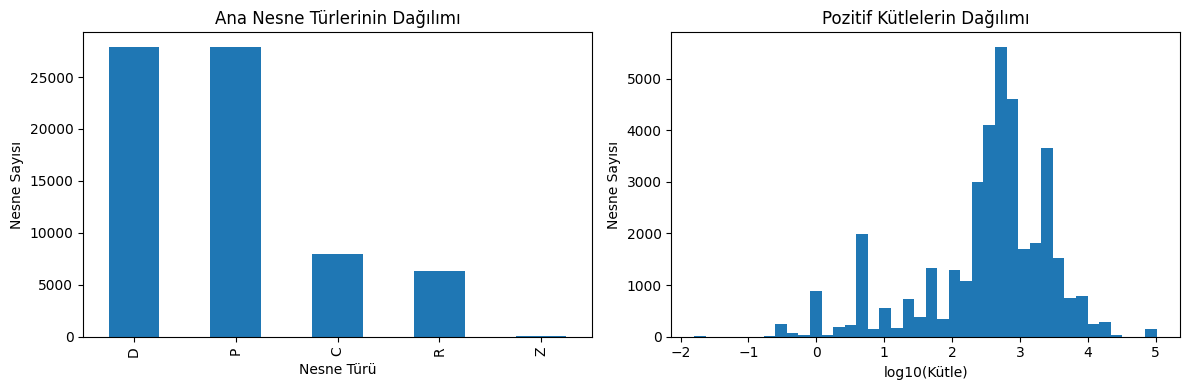

In [69]:
df_clean["Type_Main"] = df_clean["Type"].str.strip().str[0]

type_counts = df_clean["Type_Main"].value_counts()

display(type_counts.to_frame("Nesne Sayısı"))

mass_positive = pd.to_numeric(
    df_clean["Mass"].str.strip(),
    errors="coerce"
)

mass_positive = mass_positive[mass_positive > 0]

print("Pozitif kütle kaydı:", len(mass_positive))
print("\nKütle istatistikleri:")
display(mass_positive.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

type_counts.head(10).plot.bar(ax=axes[0])
axes[0].set_title("Ana Nesne Türlerinin Dağılımı")
axes[0].set_xlabel("Nesne Türü")
axes[0].set_ylabel("Nesne Sayısı")

axes[1].hist(np.log10(mass_positive), bins=40)
axes[1].set_title("Pozitif Kütlelerin Dağılımı")
axes[1].set_xlabel("log10(Kütle)")
axes[1].set_ylabel("Nesne Sayısı")

plt.tight_layout()
plt.show()

### Hedef değişkenlere ilişkin bulgular

Nesne türlerinde D ve P gruplarının çoğunlukta olduğunu, Z grubunun ise yalnızca 26 kayıt içerdiğini gördüm. Bu nedenle sınıflandırmada yeterli örneğe sahip ana grupları kullanmayı planlıyorum.

Kütle değerlerinde ortalamanın medyandan yüksek olması, dağılımın büyük değerlere doğru uzandığını gösteriyor. Regresyonda bu farklılığı dikkate alacağım.

## 6. Verinin modelleme için hazırlanması

Sınıflandırma ve regresyon problemleri için ayrı veri kümeleri oluşturacağım. Sınıflandırmada dört ana nesne grubunu kullanacağım. Regresyonda ise pozitif kütle değerlerine sahip kayıtları seçeceğim.

Modellemede veri sızıntısını önlemek için hedef değişkenleri ve hedefle doğrudan ilişkili sütunları girdi özelliklerinden çıkaracağım.

In [70]:
classification_df = df_clean[
    df_clean["Type_Main"].isin(["D", "P", "C", "R"])
].copy()

regression_df = df_clean.copy()
regression_df["Mass"] = pd.to_numeric(
    regression_df["Mass"].str.strip(),
    errors="coerce"
)
regression_df = regression_df[
    regression_df["Mass"] > 0
].copy()

print("Sınıflandırma veri boyutu:", classification_df.shape)
print("Regresyon veri boyutu:", regression_df.shape)

display(classification_df["Type_Main"].value_counts())
display(regression_df["Mass"].describe())

Sınıflandırma veri boyutu: (69973, 43)
Regresyon veri boyutu: (37946, 43)


,count
Type_Main,
D,27908
P,27852
C,7922
R,6291


,Mass
count,37946.000000
mean,1624.568612
std,6302.365764
min,0.016000
25%,150.000000
50%,575.000000
75%,1250.000000
max,104420.000000


## 7. Veri temizleme

GCAT verisindeki boş alanları ve eksik değer işaretlerini düzenleyeceğim. Ardından sayısal değişkenlerin veri tiplerini kontrol ederek modelleme için uygun hale getireceğim.

In [71]:
veri_temiz = df.copy()

veri_temiz = veri_temiz.apply(
    lambda sutun: sutun.str.strip()
)

veri_temiz = veri_temiz.mask(
    veri_temiz.isin(["", "-", "?", "N/A", "NA"])
)

sayisal_sutunlar = [
    "Mass", "DryMass", "TotMass",
    "Length", "Diameter", "Span",
    "Perigee", "Apogee", "Inc"
]

for sutun in sayisal_sutunlar:
    veri_temiz[sutun] = pd.to_numeric(
        veri_temiz[sutun],
        errors="coerce"
    )

veri_temiz["Type_Main"] = veri_temiz["Type"].str[0]

print("Veri boyutu:", veri_temiz.shape)
print("Tekrar eden kayıt:", veri_temiz.duplicated().sum())

display(
    veri_temiz[sayisal_sutunlar]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .to_frame("Eksik Oranı (%)")
)

display(veri_temiz[sayisal_sutunlar].describe().T.round(2))

Veri boyutu: (69999, 43)
Tekrar eden kayıt: 0


,Eksik Oranı (%)
Mass,0.0
DryMass,0.0
TotMass,0.0
Length,0.0
Diameter,0.0
Span,0.0
Perigee,0.0
Apogee,0.0
Inc,0.0


,count,mean,std,min,25%,50%,75%,max
Mass,69999.0,880.67,4710.28,0.0,0.00,5.0,575.00,104420.00
DryMass,69999.0,646.37,3978.79,0.0,0.00,5.0,530.00,97198.00
TotMass,69999.0,829.85,5089.72,0.0,0.00,1.0,575.00,117440.00
Length,69999.0,1.31,2.97,0.0,0.00,0.2,1.00,41.00
Diameter,69999.0,1.27,1.85,0.0,0.00,0.1,2.70,41.00
Span,69999.0,6.67,105.15,0.0,0.00,0.3,8.60,19695.00
Perigee,69998.0,1669.93,6311.46,-1600.0,265.00,456.0,740.00,244195.00
Apogee,69998.0,inf,NaN,-4788696.0,334.00,594.0,989.00,inf
Inc,69998.0,68.52,25.32,0.0,51.97,70.0,96.42,150.97


### Eksik değerler ve aykırı değerler

Sayısal değişkenlerdeki eksik değer oranlarını ve dağılımları inceleyeceğim. Ayrıca negatif, sıfır ve uç değerleri kontrol ederek hangi kayıtların modellemede kullanılabileceğini değerlendireceğim.

,Eksik,Negatif,Sıfır,Pozitif
Mass,0,0,32053,37946
DryMass,0,0,32054,37945
TotMass,0,0,34260,35739
Length,0,0,32223,37776
Diameter,0,0,32122,37877
Span,0,0,32014,37985
Perigee,1,18,10,69970
Apogee,1,170,7,69821
Inc,1,0,48,69950


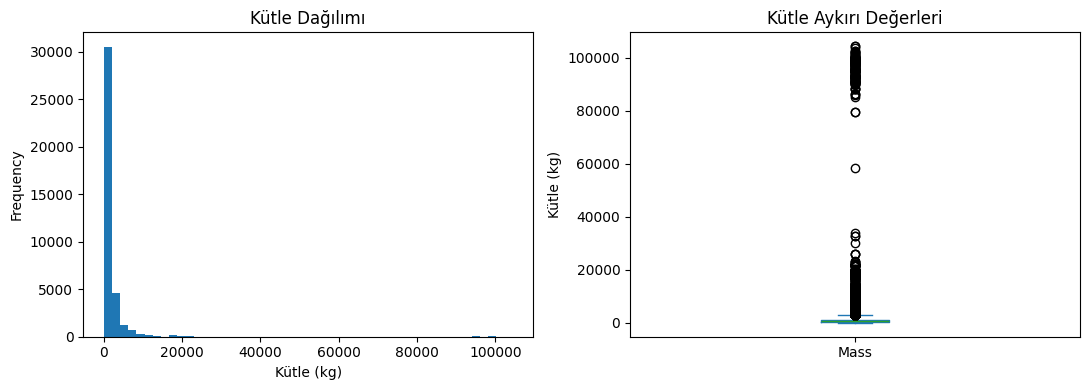

In [72]:
kontrol = pd.DataFrame({
    "Eksik": veri_temiz[sayisal_sutunlar].isna().sum(),
    "Negatif": veri_temiz[sayisal_sutunlar].lt(0).sum(),
    "Sıfır": veri_temiz[sayisal_sutunlar].eq(0).sum(),
    "Pozitif": veri_temiz[sayisal_sutunlar].gt(0).sum()
})

display(kontrol)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

veri_temiz["Mass"].loc[
    veri_temiz["Mass"] > 0
].plot.hist(bins=50, ax=axes[0])

axes[0].set_title("Kütle Dağılımı")
axes[0].set_xlabel("Kütle (kg)")

veri_temiz["Mass"].loc[
    veri_temiz["Mass"] > 0
].plot.box(ax=axes[1])

axes[1].set_title("Kütle Aykırı Değerleri")
axes[1].set_ylabel("Kütle (kg)")

plt.tight_layout()
plt.show()

### Geçersiz ve uç değerlerin kontrolü

Veri kümesinde sıfır kütle değerleri, negatif yörünge parametreleri ve sonsuz değerler tespit ettim. Bu değerleri inceleyerek modelleme açısından uygun olmayan kayıtları belirleyeceğim.

Uç değerleri doğrudan silmek yerine dağılımlarını değerlendireceğim.

In [73]:
print("Sonsuz değer sayıları:")
display(
    pd.Series(
        np.isinf(veri_temiz[sayisal_sutunlar]).sum(),
        name="Sonsuz Değer"
    ).to_frame()
)

print("Negatif yörünge değerleri:")
display(
    veri_temiz.loc[
        (veri_temiz["Perigee"] < 0) |
        (veri_temiz["Apogee"] < 0),
        ["Type", "Status", "Primary", "Perigee", "Apogee", "Inc"]
    ].head(15)
)

print("Sıfır kütlelerin nesne türlerine göre dağılımı:")
display(
    veri_temiz.loc[
        veri_temiz["Mass"] == 0,
        "Type_Main"
    ].value_counts()
)

Sonsuz değer sayıları:


,Sonsuz Değer
Mass,0
DryMass,0
TotMass,0
Length,0
Diameter,0
Span,0
Perigee,0
Apogee,51
Inc,0


Negatif yörünge değerleri:


,Type,Status,Primary,Perigee,Apogee,Inc
20,P D D,DSO,Earth,-630.0,516120.0,65.00
26,P D D,DSO,Earth,-455.0,-142121.0,24.60
109,P,R,Earth,-870.0,113860.0,35.89
110,P,R,Earth,-70.0,102200.0,28.50
111,P D D,DSO,Earth,-370.0,-242160.0,65.00
112,P D D,DSO,Earth,-45.0,-393400.0,29.00
113,P D D,DSO,Earth,-371.0,-354774.0,65.30
373,P D D,DSO,Earth,197.0,-100773.0,32.03
374,R2 D D,DSO,Earth,197.0,-100773.0,32.03
922,P D D,DSO,Earth,180.0,-210700.0,31.07


Sıfır kütlelerin nesne türlerine göre dağılımı:


,count
Type_Main,
D,27869
C,4153
Z,22
P,9


### Sayısal verilerin düzenlenmesi

Sonsuz değerleri eksik değer olarak işaretleyeceğim. Kütle tahmininde sıfır değerleri hedef değişken olarak kullanmayacağım.

Negatif yörünge değerlerini ise nesnenin fiziksel durumuyla ilişkili olabileceğinden önce inceleyeceğim.

In [74]:
veri_temiz[sayisal_sutunlar] = veri_temiz[
    sayisal_sutunlar
].replace([np.inf, -np.inf], np.nan)

print("Temizlik sonrası eksik değerler:")
display(
    veri_temiz[sayisal_sutunlar]
    .isna()
    .sum()
    .to_frame("Eksik Sayısı")
)

print("Pozitif kütleli kayıt:", (veri_temiz["Mass"] > 0).sum())
print("Sonsuz değer kaldı mı:", np.isinf(veri_temiz[sayisal_sutunlar]).any().any())

Temizlik sonrası eksik değerler:


,Eksik Sayısı
Mass,0
DryMass,0
TotMass,0
Length,0
Diameter,0
Span,0
Perigee,1
Apogee,52
Inc,1


Pozitif kütleli kayıt: 37946
Sonsuz değer kaldı mı: False


### Veri temizleme sonuçları

Veri kümesindeki sonsuz değerleri eksik değer olarak işaretledim. Kütlesi sıfır olan kayıtları regresyon hedefi için uygun bulmadım.

Negatif yörünge değerlerini ve yüksek kütleli nesneleri doğrudan silmedim. Bu değerlerin nesnelerin özellikleriyle ilişkili olabileceğini dikkate aldım.

## 8. Veri görselleştirme

Nesne türlerinin dağılımını ve sayısal değişkenler arasındaki ilişkileri inceleyeceğim. Bu grafikler, modelleme öncesinde veri yapısını daha iyi anlamamı sağlayacak.

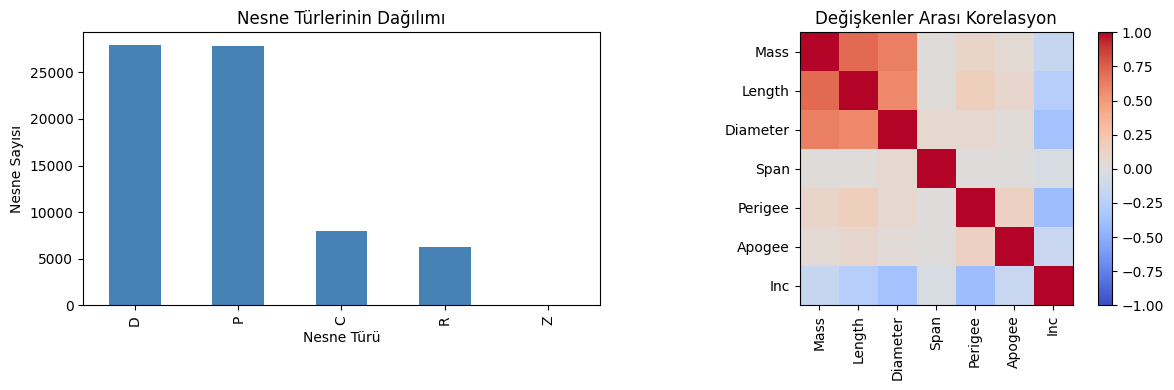

,Mass,Length,Diameter,Span,Perigee,Apogee,Inc
Mass,1.00,0.71,0.62,0.02,0.10,0.05,-0.16
Length,0.71,1.00,0.58,0.02,0.16,0.08,-0.26
Diameter,0.62,0.58,1.00,0.07,0.08,0.03,-0.36
Span,0.02,0.02,0.07,1.00,0.01,0.00,-0.04
Perigee,0.10,0.16,0.08,0.01,1.00,0.14,-0.41
Apogee,0.05,0.08,0.03,0.00,0.14,1.00,-0.14
Inc,-0.16,-0.26,-0.36,-0.04,-0.41,-0.14,1.00


In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

veri_temiz["Type_Main"].value_counts().plot.bar(
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Nesne Türlerinin Dağılımı")
axes[0].set_xlabel("Nesne Türü")
axes[0].set_ylabel("Nesne Sayısı")

korelasyon = veri_temiz[
    ["Mass", "Length", "Diameter", "Span", "Perigee", "Apogee", "Inc"]
].corr()

im = axes[1].imshow(
    korelasyon,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

axes[1].set_xticks(range(len(korelasyon.columns)))
axes[1].set_yticks(range(len(korelasyon.columns)))
axes[1].set_xticklabels(korelasyon.columns, rotation=90)
axes[1].set_yticklabels(korelasyon.columns)
axes[1].set_title("Değişkenler Arası Korelasyon")

plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

display(korelasyon.round(2))

### Görselleştirme bulguları

Nesne türlerinin dağılımında D ve P gruplarının çoğunlukta olduğunu gözlemledim. Kütle ile uzunluk ve çap arasında pozitif ilişki bulunurken yörünge eğikliği bazı değişkenlerle negatif ilişki göstermektedir.

Bu sonuçları dikkate alarak model girdilerini belirleyeceğim.

## 9. Özellik seçimi ve veri sızıntısının önlenmesi

Sınıflandırma ve regresyon için fiziksel boyutları ve yörünge özelliklerini kullanacağım. Hedef değişkenleri, hedefle doğrudan ilişkili kütle sütunlarını ve nesne kimliklerini model girdilerinden çıkaracağım.

In [76]:
features = [
    "Length", "Diameter", "Span",
    "Perigee", "Apogee", "Inc"
]

classification_data = veri_temiz[
    veri_temiz["Type_Main"].isin(["D", "P", "C", "R"])
].copy()

regression_data = veri_temiz[
    veri_temiz["Mass"] > 0
].copy()

X_cls = classification_data[features]
y_cls = classification_data["Type_Main"]

X_reg = regression_data[features]
y_reg = regression_data["Mass"]

print("Sınıflandırma:", X_cls.shape, y_cls.shape)
print("Regresyon:", X_reg.shape, y_reg.shape)

display(
    pd.DataFrame({
        "Sınıflandırma Eksik (%)": X_cls.isna().mean() * 100,
        "Regresyon Eksik (%)": X_reg.isna().mean() * 100
    }).round(2)
)

Sınıflandırma: (69973, 6) (69973,)
Regresyon: (37946, 6) (37946,)


,Sınıflandırma Eksik (%),Regresyon Eksik (%)
Length,0.00,0.00
Diameter,0.00,0.00
Span,0.00,0.00
Perigee,0.00,0.00
Apogee,0.07,0.14
Inc,0.00,0.00


## 10. Eğitim, doğrulama ve test ayrımı

Verileri %80 eğitim ve %20 test olarak ayırdım. Sınıflandırmada sınıf dağılımlarını korumak için tabakalı ayırma kullandım.

Eğitim verisi üzerinde 5 katlı çapraz doğrulama (5-Fold Cross-Validation) uyguladım. Her aşamada dört kat eğitim, bir kat doğrulama için kullanılır. Böylece modelleri farklı veri bölümlerinde değerlendirerek karşılaştırdım.

Test verisini model seçimi sırasında kullanmadım; yalnızca son değerlendirme için ayırdım.

In [77]:
from sklearn.model_selection import train_test_split

X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls, y_cls,
    test_size=0.20,
    random_state=SEED,
    stratify=y_cls
)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg,
    test_size=0.20,
    random_state=SEED
)

print("Sınıflandırma eğitim:", X_cls_train.shape)
print("Sınıflandırma test:", X_cls_test.shape)

print("Regresyon eğitim:", X_reg_train.shape)
print("Regresyon test:", X_reg_test.shape)

display(
    pd.DataFrame({
        "Eğitim (%)": y_cls_train.value_counts(normalize=True) * 100,
        "Test (%)": y_cls_test.value_counts(normalize=True) * 100
    }).round(2)
)

Sınıflandırma eğitim: (55978, 6)
Sınıflandırma test: (13995, 6)
Regresyon eğitim: (30356, 6)
Regresyon test: (7590, 6)


,Eğitim (%),Test (%)
Type_Main,,
D,39.88,39.89
P,39.80,39.81
C,11.32,11.32
R,8.99,8.99


## 11. Ön işleme

Eksik sayısal değerleri eğitim verisinden hesaplanan medyanla dolduracağım. Ardından değişkenleri standartlaştıracağım.

Bu işlemleri Pipeline içinde uygulayarak çapraz doğrulama ve test aşamalarında veri sızıntısını önleyeceğim.

In [78]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

## 12. Sınıflandırma Modellerinin Eğitilmesi

GCAT veri kümesindeki yapay uzay nesnelerini fiziksel boyutları (Length, Diameter, Span) ve yörünge özellikleri (Perigee, Apogee, Inc) kullanarak D, P, C ve R sınıflarına ayırmayı amaçladım.

Farklı öğrenme yaklaşımlarını karşılaştırmak için dört model seçtim:

- **Dummy Classifier:** En sık görülen sınıfı tahmin eden başlangıç modeli.
- **Lojistik Regresyon:** Doğrusal karar sınırlarının sınıflandırma başarısını değerlendirmek için.
- **Random Forest:** Fiziksel ve yörüngesel özellikler arasındaki doğrusal olmayan ilişkileri öğrenmek için.
- **Yapay Sinir Ağı (ANN):** Daha karmaşık ilişkileri öğrenmek ve farklı sinir ağı mimarilerini karşılaştırmak için.

Modelleri eğitim verisi üzerinde 5 katlı çapraz doğrulama ile değerlendirdim. Sınıf dağılımları eşit olmadığı için model seçiminde Macro F1 değerini esas aldım. Test verisini model seçiminde kullanmadım.

In [79]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

classification_models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Lojistik Regresyon": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "ANN 32": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", MLPClassifier(
            hidden_layer_sizes=(32,),
            max_iter=300,
            random_state=SEED
        ))
    ]),

    "ANN 64-32": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=300,
            random_state=SEED
        ))
    ])
}

classification_results = []

for name, model in classification_models.items():
    scores = cross_validate(
        model,
        X_cls_train,
        y_cls_train,
        cv=cv_cls,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision_macro",
            "Recall": "recall_macro",
            "Macro F1": "f1_macro"
        },
        n_jobs=-1
    )

    classification_results.append({
        "Model": name,
        "CV Accuracy": scores["test_Accuracy"].mean(),
        "CV Precision": scores["test_Precision"].mean(),
        "CV Recall": scores["test_Recall"].mean(),
        "CV Macro F1": scores["test_Macro F1"].mean(),
        "CV F1 Std": scores["test_Macro F1"].std()
    })

classification_cv_results = (
    pd.DataFrame(classification_results)
    .sort_values("CV Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(classification_cv_results.round(4).style.hide(axis="index"))

Model,CV Accuracy,CV Precision,CV Recall,CV Macro F1,CV F1 Std
Random Forest,0.965300,0.958000,0.937400,0.946700,0.003200
ANN 64-32,0.924000,0.899800,0.860300,0.873500,0.003100
ANN 32,0.905700,0.870800,0.825800,0.837800,0.012600
Lojistik Regresyon,0.810500,0.683500,0.642000,0.651300,0.011000
Dummy Classifier,0.398800,0.099700,0.250000,0.142600,0.000000


## 13. Sınıflandırma sonuçları

Çapraz doğrulama sonrasında modelleri eğitim verisinin tamamıyla yeniden eğittim. Eğitim ve test kümeleri için Accuracy, Precision, Recall ve Macro F1 değerlerini hesapladım.

Eğitim ve test başarılarını karşılaştırarak modellerin genelleme performansını ve olası aşırı öğrenme durumlarını inceleyeceğim. Test sonuçlarını model seçimi veya hiperparametre ayarı için kullanmadım.

In [80]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

sinif_sonuclari = []
sinif_tahminleri = {}

for isim, model in classification_models.items():
    model.fit(X_cls_train, y_cls_train)

    egitim_tahmini = model.predict(X_cls_train)
    test_tahmini = model.predict(X_cls_test)

    sinif_tahminleri[isim] = test_tahmini

    for bolum, gercek, tahmin in [
        ("Eğitim", y_cls_train, egitim_tahmini),
        ("Test", y_cls_test, test_tahmini)
    ]:
        sinif_sonuclari.append({
            "Model": isim,
            "Bölüm": bolum,
            "Accuracy": accuracy_score(gercek, tahmin),
            "Precision": precision_score(
                gercek, tahmin, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                gercek, tahmin, average="macro", zero_division=0
            ),
            "Macro F1": f1_score(
                gercek, tahmin, average="macro", zero_division=0
            )
        })

sinif_sonuc = pd.DataFrame(sinif_sonuclari)

display(sinif_sonuc.round(4).style.hide(axis="index"))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Model,Bölüm,Accuracy,Precision,Recall,Macro F1
Dummy Classifier,Eğitim,0.398800,0.099700,0.250000,0.142600
Dummy Classifier,Test,0.398900,0.099700,0.250000,0.142600
Lojistik Regresyon,Eğitim,0.812900,0.689100,0.648500,0.658100
Lojistik Regresyon,Test,0.815800,0.698700,0.650100,0.662500
Random Forest,Eğitim,0.999900,0.999700,0.999800,0.999800
Random Forest,Test,0.967200,0.960700,0.940300,0.949500
ANN 32,Eğitim,0.910200,0.881900,0.831500,0.845700
ANN 32,Test,0.906500,0.875300,0.823800,0.838500
ANN 64-32,Eğitim,0.925300,0.890700,0.877200,0.881800
ANN 64-32,Test,0.922000,0.884000,0.870400,0.874900


In [81]:
sinif_ozet = sinif_sonuc.pivot(
    index="Model",
    columns="Bölüm",
    values="Macro F1"
)

sinif_ozet = sinif_ozet.join(
    classification_cv_results.set_index("Model")[["CV Macro F1", "CV F1 Std"]]
)

sinif_ozet["F1 Farkı"] = sinif_ozet["Eğitim"] - sinif_ozet["Test"]

sinif_ozet = sinif_ozet[
    ["CV Macro F1", "CV F1 Std", "Eğitim", "Test", "F1 Farkı"]
].sort_values("CV Macro F1", ascending=False)

display(sinif_ozet.round(4))

,CV Macro F1,CV F1 Std,Eğitim,Test,F1 Farkı
Model,,,,,
Random Forest,0.9467,0.0032,0.9998,0.9495,0.0502
ANN 64-32,0.8735,0.0031,0.8818,0.8749,0.0068
ANN 32,0.8378,0.0126,0.8457,0.8385,0.0073
Lojistik Regresyon,0.6513,0.0110,0.6581,0.6625,-0.0044
Dummy Classifier,0.1426,0.0000,0.1426,0.1426,-0.0000


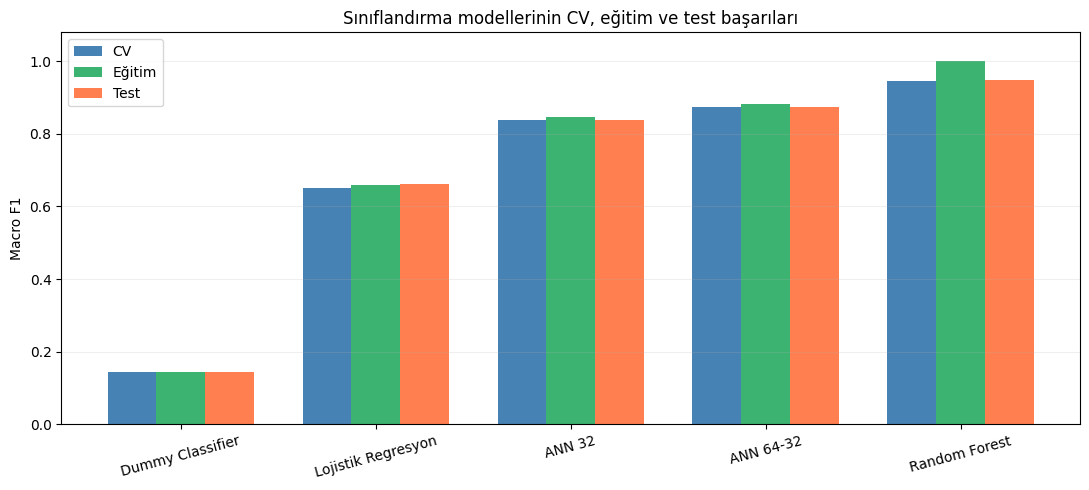

In [82]:
import matplotlib.pyplot as plt
import numpy as np

grafik_verisi = sinif_ozet.sort_values("CV Macro F1")

x = np.arange(len(grafik_verisi))
genislik = 0.25

plt.figure(figsize=(11, 5))

plt.bar(
    x - genislik,
    grafik_verisi["CV Macro F1"],
    genislik,
    label="CV",
    color="steelblue"
)

plt.bar(
    x,
    grafik_verisi["Eğitim"],
    genislik,
    label="Eğitim",
    color="mediumseagreen"
)

plt.bar(
    x + genislik,
    grafik_verisi["Test"],
    genislik,
    label="Test",
    color="coral"
)

plt.xticks(x, grafik_verisi.index, rotation=15)
plt.ylabel("Macro F1")
plt.ylim(0, 1.08)
plt.title("Sınıflandırma modellerinin CV, eğitim ve test başarıları")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Seçilen model: Random Forest
              precision    recall  f1-score   support

           D       0.96      0.98      0.97      5582
           P       0.99      0.99      0.99      5571
           C       0.93      0.81      0.87      1584
           R       0.97      0.97      0.97      1258

    accuracy                           0.97     13995
   macro avg       0.96      0.94      0.95     13995
weighted avg       0.97      0.97      0.97     13995



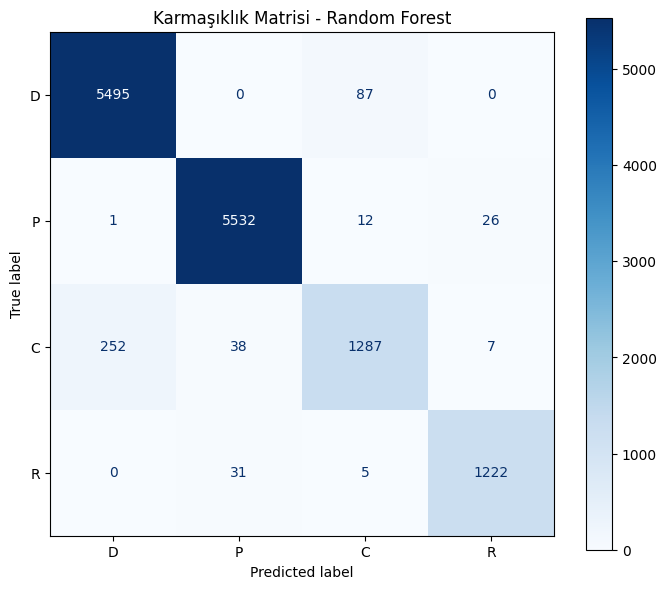

In [83]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

en_iyi_model_adi = classification_cv_results.iloc[0]["Model"]
en_iyi_tahmin = sinif_tahminleri[en_iyi_model_adi]

print("Seçilen model:", en_iyi_model_adi)

print(
    classification_report(
        y_cls_test,
        en_iyi_tahmin,
        labels=["D", "P", "C", "R"],
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_cls_test,
    en_iyi_tahmin,
    labels=["D", "P", "C", "R"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(f"Karmaşıklık Matrisi - {en_iyi_model_adi}")
plt.tight_layout()
plt.show()

In [84]:
rf_ayarlar = {
    "Mevcut Random Forest": (None, 1),
    "RF - Derinlik 20": (20, 2),
    "RF - Derinlik 15": (15, 4)
}

rf_sonuclar = []

for isim, (derinlik, yaprak) in rf_ayarlar.items():
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=derinlik,
        min_samples_leaf=yaprak,
        random_state=SEED,
        n_jobs=1
    )

    skorlar = cross_validate(
        model,
        X_cls_train,
        y_cls_train,
        cv=cv_cls,
        scoring={
            "Accuracy": "accuracy",
            "Macro F1": "f1_macro"
        },
        n_jobs=-1,
        return_train_score=True
    )

    rf_sonuclar.append({
        "Model": isim,
        "CV Accuracy": skorlar["test_Accuracy"].mean(),
        "CV Macro F1": skorlar["test_Macro F1"].mean(),
        "CV F1 Std": skorlar["test_Macro F1"].std(),
        "Eğitim F1": skorlar["train_Macro F1"].mean(),
        "CV F1 Farkı": (
            skorlar["train_Macro F1"].mean()
            - skorlar["test_Macro F1"].mean()
        )
    })

rf_karsilastirma = pd.DataFrame(rf_sonuclar)

display(
    rf_karsilastirma
    .sort_values("CV Macro F1", ascending=False)
    .round(4)
    .style.hide(axis="index")
)

Model,CV Accuracy,CV Macro F1,CV F1 Std,Eğitim F1,CV F1 Farkı
Mevcut Random Forest,0.965300,0.946600,0.003500,0.999800,0.053200
RF - Derinlik 20,0.963200,0.942300,0.003400,0.978800,0.036500
RF - Derinlik 15,0.958800,0.934500,0.002400,0.955500,0.021000


### Hiperparametre denemesi bulguları

Random Forest için ağaç derinliği ve yaprak başına minimum örnek sayısını değiştirdim.

Ağaçların karmaşıklığını sınırlandırmak eğitim ve doğrulama başarıları arasındaki farkı azalttı. Ancak CV Macro F1 değeri 0,9466'dan sırasıyla 0,9423 ve 0,9345'e düştü.

Bu nedenle en yüksek çapraz doğrulama başarısını sağlayan başlangıç ayarlarını korudum. Modelin test başarısı %96,72 Accuracy ve 0,9495 Macro F1 olarak elde edildi.

Ağaç derinliğini sınırlandırmak eğitim–doğrulama farkını azaltsa da CV başarısını düşürdüğünden başlangıç modelini korudum.

## 16. Regresyon Analizi

Bu bölümde uzay nesnelerinin fiziksel boyutları ve yörünge özelliklerinden yararlanarak kütlelerini (`Mass`) tahmin edeceğim.

Regresyon için kütlesi sıfırdan büyük olan kayıtları kullandım. Verileri daha önce %80 eğitim ve %20 test olarak ayırdım.

Öncelikle hedef değişkenin dağılımını inceleyerek modelleme yaklaşımını belirleyeceğim.

Regresyon veri sayısı: 37946
Eğitim: 30356
Test: 7590


,Mass
count,30356.000000
mean,1614.468722
std,6142.580291
min,0.016000
25%,150.000000
50%,575.000000
75%,1250.000000
90%,3108.500000
95%,5500.000000
99%,17490.000000


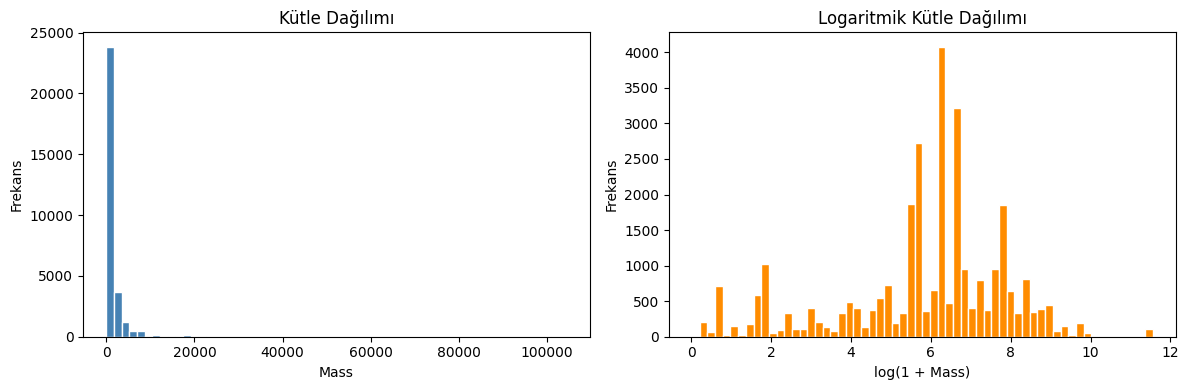

In [85]:
print("Regresyon veri sayısı:", len(regression_data))
print("Eğitim:", len(X_reg_train))
print("Test:", len(X_reg_test))

display(
    y_reg_train.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("Mass")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_reg_train, bins=60, color="steelblue", edgecolor="white")
axes[0].set_title("Kütle Dağılımı")
axes[0].set_xlabel("Mass")
axes[0].set_ylabel("Frekans")

axes[1].hist(np.log1p(y_reg_train), bins=60, color="darkorange", edgecolor="white")
axes[1].set_title("Logaritmik Kütle Dağılımı")
axes[1].set_xlabel("log(1 + Mass)")
axes[1].set_ylabel("Frekans")

plt.tight_layout()
plt.show()

### Kütle dağılımı bulguları

Kütle değerlerinin sağa çarpık dağıldığını ve az sayıdaki çok büyük değerin dağılımı etkilediğini gözlemledim.

Logaritmik dönüşüm, büyük değerlerin etkisini azaltarak dağılımı daha dengeli hâle getirdi. Bu nedenle regresyon modellerinde logaritmik hedef dönüşümünün etkisini de karşılaştıracağım.

## 17. Regresyon Modellerinin Çapraz Doğrulama ile Karşılaştırılması

Kütle tahmini için Dummy Regressor, Ridge Regression ve Random Forest modellerini karşılaştıracağım.

Random Forest modelinde logaritmik hedef dönüşümünün yanı sıra ağaç derinliği, yaprak başına minimum örnek sayısı ve kullanılan özellik sayısının etkisini inceleyeceğim.

Modelleri eğitim verisinde 5 katlı çapraz doğrulama ile değerlendireceğim. Eksik değer doldurma ve ölçeklendirme işlemlerini Pipeline içerisinde uygulayarak veri sızıntısını önleyeceğim.

Model seçiminde CV RMSE değerini esas alacağım.

In [86]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)

regression_models = {
    "Dummy Regressor": DummyRegressor(strategy="median"),

    "Ridge Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "Random Forest + Log": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", RandomForestRegressor(
                n_estimators=100,
                random_state=SEED,
                n_jobs=1
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    "RF - Derinlik 25": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=25,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "RF - Derinlik 20": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "RF - Derinlik 20 + Özellik": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=2,
            max_features=0.8,
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "RF - Derinlik 15 + Özellik": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=SEED,
            n_jobs=1
        ))
    ])
}

regression_results = []

for name, model in regression_models.items():
    scores = cross_validate(
        model,
        X_reg_train,
        y_reg_train,
        cv=cv_reg,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=-1
    )

    cv_rmse = np.sqrt(-scores["test_MSE"]).mean()
    train_rmse = np.sqrt(-scores["train_MSE"]).mean()

    regression_results.append({
        "Model": name,
        "CV MAE": -scores["test_MAE"].mean(),
        "CV MSE": -scores["test_MSE"].mean(),
        "CV RMSE": cv_rmse,
        "CV R2": scores["test_R2"].mean(),
        "Eğitim RMSE": train_rmse,
        "RMSE Farkı": cv_rmse - train_rmse
    })

regression_cv_results = pd.DataFrame(regression_results)
regression_cv_results = regression_cv_results.sort_values(
    "CV RMSE"
).reset_index(drop=True)

display(
    regression_cv_results.round(4).style.hide(axis="index")
)

en_iyi_regresyon_adi = regression_cv_results.iloc[0]["Model"]
print("CV sonuçlarına göre seçilen model:", en_iyi_regresyon_adi)

Model,CV MAE,CV MSE,CV RMSE,CV R2,Eğitim RMSE,RMSE Farkı
Random Forest,158.212800,1151026.030600,1002.384700,0.963400,393.301500,609.083300
RF - Derinlik 20 + Özellik,167.107900,1156710.526900,1017.853100,0.963900,555.511200,462.341900
RF - Derinlik 20,167.856400,1223718.554800,1030.542100,0.960900,581.315900,449.226100
RF - Derinlik 25,168.132200,1273772.605300,1048.044000,0.959200,581.590500,466.453500
Random Forest + Log,152.344700,1227369.394600,1073.622500,0.962800,418.525100,655.097500
RF - Derinlik 15 + Özellik,196.823300,1430844.327000,1152.463500,0.956300,883.239300,269.224100
Ridge Regression,2236.645800,12746410.980400,3567.344700,0.647800,3541.679700,25.665000
Dummy Regressor,1420.575600,38810614.406800,6193.434000,-0.029200,6227.482400,-34.048400


CV sonuçlarına göre seçilen model: Random Forest


### Çapraz doğrulama bulguları

Random Forest, 1002,38 CV RMSE ve 0,9634 CV R² değerleriyle en başarılı model oldu.

Hiperparametreleri değiştirilmiş Random Forest modelinde eğitim ve doğrulama hataları arasındaki fark azaldı. Ancak CV RMSE değeri 1017,85'e yükseldi.

Bu nedenle daha düşük doğrulama hatası sağlayan standart Random Forest modelini seçtim.

## 18. Regresyon Modellerinin Eğitim ve Test Performansları

Çapraz doğrulama sonucunda belirlenen modelleri eğitim verisinin tamamında eğiterek eğitim ve test performanslarını karşılaştıracağım.

MAE, MSE, RMSE ve R² metriklerini hesaplayarak modellerin tahmin başarısını ve genelleme durumlarını değerlendireceğim.

In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regresyon_sonuclari = []
regresyon_tahminleri = {}

for isim, model in regression_models.items():
    model.fit(X_reg_train, y_reg_train)

    egitim_tahmini = model.predict(X_reg_train)
    test_tahmini = model.predict(X_reg_test)

    regresyon_tahminleri[isim] = test_tahmini

    for bolum, gercek, tahmin in [
        ("Eğitim", y_reg_train, egitim_tahmini),
        ("Test", y_reg_test, test_tahmini)
    ]:
        mse = mean_squared_error(gercek, tahmin)

        regresyon_sonuclari.append({
            "Model": isim,
            "Bölüm": bolum,
            "MAE": mean_absolute_error(gercek, tahmin),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2_score(gercek, tahmin)
        })

regresyon_sonuc = pd.DataFrame(regresyon_sonuclari)

display(
    regresyon_sonuc.round(4).style.hide(axis="index")
)

print("Seçilen model:", en_iyi_regresyon_adi)

display(
    regresyon_sonuc[
        regresyon_sonuc["Model"] == en_iyi_regresyon_adi
    ].round(4).style.hide(axis="index")
)

Model,Bölüm,MAE,MSE,RMSE,R2
Dummy Regressor,Eğitim,1420.575000,38810544.901600,6229.811000,-0.028600
Dummy Regressor,Test,1468.031900,48858569.943800,6989.890600,-0.024900
Ridge Regression,Eğitim,2234.505100,12564617.645600,3544.660400,0.667000
Ridge Regression,Test,2252.771200,14843451.671900,3852.720000,0.688600
Random Forest,Eğitim,56.512100,139209.310800,373.107600,0.996300
Random Forest,Test,151.242500,1475771.333300,1214.813300,0.969000
Random Forest + Log,Eğitim,58.820900,185508.474600,430.706900,0.995100
Random Forest + Log,Test,147.776200,2116152.606900,1454.700200,0.955600
RF - Derinlik 25,Eğitim,83.852300,346821.714900,588.915700,0.990800
RF - Derinlik 25,Test,158.762900,1387543.881900,1177.940500,0.970900


Seçilen model: Random Forest


Model,Bölüm,MAE,MSE,RMSE,R2
Random Forest,Eğitim,56.512100,139209.310800,373.107600,0.996300
Random Forest,Test,151.242500,1475771.333300,1214.813300,0.969000


### Regresyon performansının değerlendirilmesi

Standart Random Forest, test verisinde 151,24 MAE, 1214,81 RMSE ve 0,9690 R² değerlerine ulaştı.

Ayarlanmış Random Forest modelinde eğitim ve test performansları arasındaki fark azalsa da çapraz doğrulama RMSE değeri standart modele göre daha yüksek kaldı.

Standart Random Forest'ın CV R² (0,9634) ve test R² (0,9690) değerlerinin birbirine yakın olması, mevcut veri ayrımında yüksek genelleme başarısı gösterdiğini ortaya koydu.

## 19. Gerçek ve Tahmin Edilen Kütle Değerlerinin Karşılaştırılması

Dummy Regressor, Ridge Regression ve Random Forest modellerinin test verisindeki tahminlerini gerçek kütle değerleriyle karşılaştıracağım.

Kesikli çizgi ideal tahmini temsil etmektedir. Noktaların bu çizgiye yakın olması, tahmin hatasının daha düşük olduğunu gösterir.

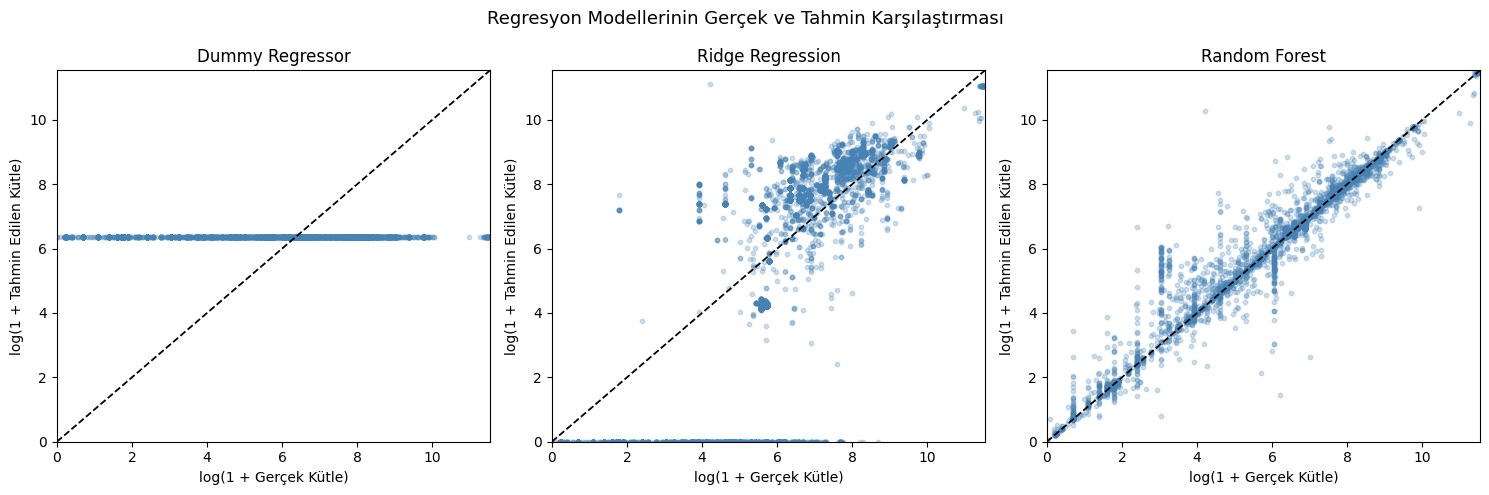

In [88]:
model_isimleri = [
    "Dummy Regressor",
    "Ridge Regression",
    "Random Forest"
]

gercek = y_reg_test.to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, isim in zip(axes, model_isimleri):
    tahmin = regresyon_tahminleri[isim]

    ax.scatter(
        np.log1p(gercek),
        np.log1p(np.maximum(tahmin, 0)),
        alpha=0.25,
        s=10,
        color="steelblue"
    )

    ust_sinir = np.log1p(
        max(gercek.max(), np.maximum(tahmin, 0).max())
    )

    ax.plot(
        [0, ust_sinir],
        [0, ust_sinir],
        "k--",
        linewidth=1.3
    )

    ax.set_xlim(0, ust_sinir)
    ax.set_ylim(0, ust_sinir)
    ax.set_title(isim)
    ax.set_xlabel("log(1 + Gerçek Kütle)")
    ax.set_ylabel("log(1 + Tahmin Edilen Kütle)")

plt.suptitle(
    "Regresyon Modellerinin Gerçek ve Tahmin Karşılaştırması",
    fontsize=13
)

plt.tight_layout()
plt.show()

### Grafiklerin Değerlendirilmesi

Kütle değerleri geniş bir aralıkta dağıldığı için gerçek ve tahmin edilen değerleri logaritmik ölçekte görselleştirdim.

Dummy Regressor sabit tahminler üretirken Ridge Regression gerçek değerlerdeki değişimi kısmen yakaladı.

Random Forest tahminleri ideal tahmin çizgisine daha yakın dağıldı ve diğer modellere göre daha başarılı sonuçlar verdi.

Logaritmik ölçek yalnızca görselleştirmede kullanıldı; modellerin performans metrikleri orijinal kütle değerleri üzerinden hesaplandı.

## 20. Kümeleme Analizi

Bu bölümde uzay nesnelerini yörünge özelliklerine göre gruplandırmak için K-Means algoritmasını kullanacağım.

Kümeleme özellikleri olarak Perigee, Apogee ve Inc değerlerini seçtim. Geçersiz yörünge kayıtlarını filtreleyerek yörünge yüksekliklerine logaritmik dönüşüm uygulayacağım.

Küme sayısını Silhouette Score ve Elbow yöntemleriyle inceleyip oluşan grupları yörünge özelliklerine göre yorumlayacağım.

Küme Sayısı,Silhouette,Inertia
2,0.631800,19838.522000
3,0.490000,12061.741700
4,0.524000,7156.720300
5,0.462100,6019.271000
6,0.421700,5060.491000
7,0.389200,4509.914900
8,0.390400,3968.151500


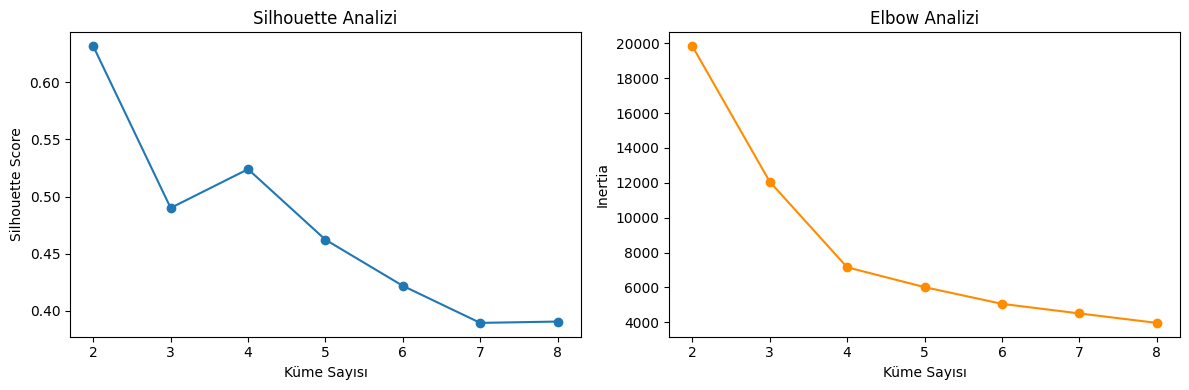

In [89]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

kume_ozellikleri = ["Perigee", "Apogee", "Inc"]

X_cluster = veri_temiz[kume_ozellikleri].copy()
X_cluster = X_cluster.replace([np.inf, -np.inf], np.nan).dropna()

X_cluster = X_cluster[
    (X_cluster["Perigee"] >= 0) &
    (X_cluster["Apogee"] >= X_cluster["Perigee"]) &
    (X_cluster["Apogee"] <= 100000)
].copy()

X_cluster_log = X_cluster.copy()
X_cluster_log[["Perigee", "Apogee"]] = np.log1p(
    X_cluster_log[["Perigee", "Apogee"]]
)

cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster_log)

rng = np.random.default_rng(SEED)
indeksler = rng.choice(len(X_cluster_scaled), size=12000, replace=False)
X_ornek = X_cluster_scaled[indeksler]

sonuclar = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=5, random_state=SEED)
    etiketler = model.fit_predict(X_ornek)

    skor = silhouette_score(
        X_ornek,
        etiketler,
        sample_size=1600,
        random_state=SEED
    )

    sonuclar.append({
        "Küme Sayısı": k,
        "Silhouette": skor,
        "Inertia": model.inertia_
    })

kume_karsilastirma = pd.DataFrame(sonuclar)
display(kume_karsilastirma.round(4).style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    kume_karsilastirma["Küme Sayısı"],
    kume_karsilastirma["Silhouette"],
    marker="o"
)
axes[0].set_title("Silhouette Analizi")
axes[0].set_xlabel("Küme Sayısı")
axes[0].set_ylabel("Silhouette Score")

axes[1].plot(
    kume_karsilastirma["Küme Sayısı"],
    kume_karsilastirma["Inertia"],
    marker="o",
    color="darkorange"
)
axes[1].set_title("Elbow Analizi")
axes[1].set_xlabel("Küme Sayısı")
axes[1].set_ylabel("Inertia")

plt.tight_layout()
plt.show()

### 20.1. K-Means Modelinin Oluşturulması

Silhouette analizinde iki küme en yüksek skoru sağladı. Ancak dört kümeli çözüm, farklı yörünge özelliklerine sahip nesneleri daha ayrıntılı incelemeye olanak tanıdı.

Bu nedenle k=4 seçerek kümelerin büyüklüklerini ve yörünge özelliklerini değerlendireceğim.

In [90]:
kmeans_final = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=SEED
)

etiketler = kmeans_final.fit_predict(X_cluster_scaled)

cluster_sonuc = X_cluster.copy()
cluster_sonuc["Küme"] = etiketler

medyanlar = cluster_sonuc.groupby("Küme")[kume_ozellikleri].median()

geo = medyanlar["Perigee"].idxmax()
transfer = medyanlar.drop(index=geo)["Apogee"].idxmax()

kalan = medyanlar.drop(index=[geo, transfer])
alcak = kalan["Inc"].idxmin()
yuksek = kalan["Inc"].idxmax()

kume_adlari = {
    alcak: "Alçak Yörünge - Düşük Eğim",
    yuksek: "Alçak Yörünge - Yüksek Eğim",
    transfer: "Eliptik / Transfer Yörüngesi",
    geo: "Jeosenkron Bölgeye Yakın"
}

cluster_sonuc["Yörünge Grubu"] = cluster_sonuc["Küme"].map(kume_adlari)

kume_ozet = cluster_sonuc.groupby("Yörünge Grubu").agg(
    Nesne_Sayısı=("Küme", "size"),
    Perigee=("Perigee", "median"),
    Apogee=("Apogee", "median"),
    Inc=("Inc", "median")
)

display(kume_ozet.round(2))
print("Oluşturulan sütunlar:", cluster_sonuc.columns.tolist())

,Nesne_Sayısı,Perigee,Apogee,Inc
Yörünge Grubu,,,,
Alçak Yörünge - Düşük Eğim,28693,265.0,322.0,53.16
Alçak Yörünge - Yüksek Eğim,33051,647.0,821.0,97.28
Eliptik / Transfer Yörüngesi,4809,454.0,33729.0,47.46
Jeosenkron Bölgeye Yakın,2901,35590.0,35794.0,2.00


Oluşturulan sütunlar: ['Perigee', 'Apogee', 'Inc', 'Küme', 'Yörünge Grubu']


### 20.2. Kümeleme Sonuçlarının Görselleştirilmesi

Oluşturulan dört yörünge grubunu nesne sayıları ve yörünge yükseklikleri bakımından karşılaştıracağım.

Grafiklerde sayısal küme etiketleri yerine grupların temel özelliklerini açıklayan isimler kullanacağım.

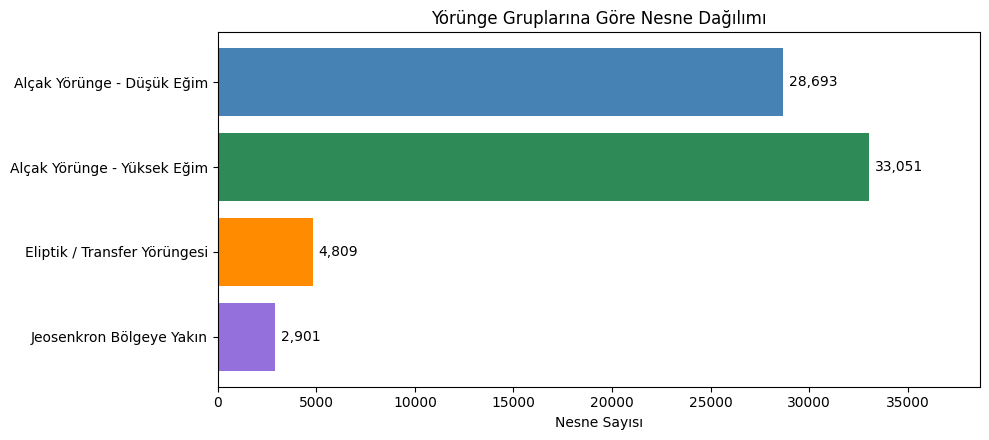

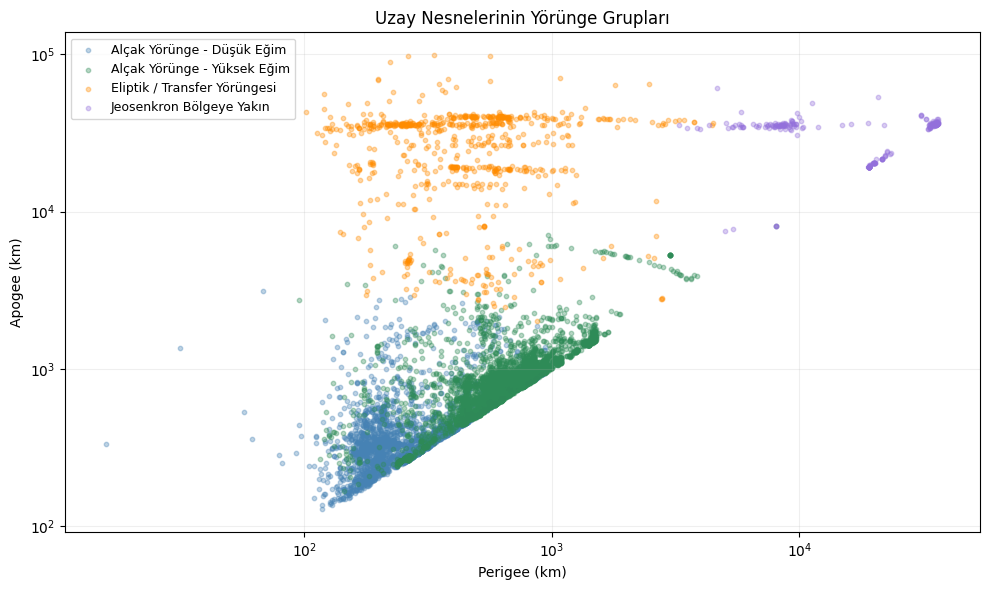

In [91]:
renkler = {
    "Alçak Yörünge - Düşük Eğim": "steelblue",
    "Alçak Yörünge - Yüksek Eğim": "seagreen",
    "Eliptik / Transfer Yörüngesi": "darkorange",
    "Jeosenkron Bölgeye Yakın": "mediumpurple"
}

sirali_gruplar = list(renkler.keys())
sayilar = cluster_sonuc["Yörünge Grubu"].value_counts().reindex(sirali_gruplar)

plt.figure(figsize=(10, 4.5))

plt.barh(
    sirali_gruplar,
    sayilar,
    color=[renkler[g] for g in sirali_gruplar]
)

plt.gca().invert_yaxis()
plt.xlabel("Nesne Sayısı")
plt.title("Yörünge Gruplarına Göre Nesne Dağılımı")

for i, sayi in enumerate(sayilar):
    plt.text(sayi + 300, i, f"{sayi:,}", va="center")

plt.xlim(0, sayilar.max() * 1.17)
plt.tight_layout()
plt.show()

ornek = cluster_sonuc.sample(
    n=min(10000, len(cluster_sonuc)),
    random_state=SEED
)

plt.figure(figsize=(10, 6))

for grup in sirali_gruplar:
    veri = ornek[ornek["Yörünge Grubu"] == grup]

    plt.scatter(
        veri["Perigee"],
        veri["Apogee"],
        s=10,
        alpha=0.35,
        color=renkler[grup],
        label=grup
    )

plt.xscale("symlog", linthresh=100)
plt.yscale("symlog", linthresh=100)

plt.xlabel("Perigee (km)")
plt.ylabel("Apogee (km)")
plt.title("Uzay Nesnelerinin Yörünge Grupları")
plt.legend(fontsize=9)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 20.3. Kümeleme Sonuçlarının Değerlendirilmesi

K-Means algoritmasıyla uzay nesnelerini yörünge özelliklerine göre dört gruba ayırdım.

- **Alçak Yörünge – Düşük Eğim:** 28.693 nesne (%41,3).
- **Alçak Yörünge – Yüksek Eğim:** 33.051 nesne (%47,6).
- **Eliptik / Transfer Yörüngesi:** 4.809 nesne (%6,9).
- **Jeosenkron Bölgeye Yakın:** 2.901 nesne (%4,2).

Nesnelerin büyük çoğunluğu alçak yörünge özellikleri gösteren iki grupta toplandı. Eliptik yörünge grubunda Perigee ve Apogee değerleri arasında belirgin farklar bulunurken jeosenkron bölgeye yakın grupta yüksek yörünge değerleri gözlemlendi.

Kümeler tamamen birbirinden ayrılmasa da yörünge özellikleri bakımından yorumlanabilir gruplar elde edildi. Küme isimleri, grupların medyan özelliklerine göre verilmiş açıklayıcı isimlerdir.

## 21. Sonuç ve Değerlendirme

**Sınıflandırma:** Uzay nesnelerini D, P, C ve R sınıflarına ayırmak için Dummy Classifier, Lojistik Regresyon, Random Forest ve iki farklı ANN mimarisini karşılaştırdım. En yüksek CV Macro F1 değerini 0,9467 ile Random Forest elde etti. ANN (32) için CV Macro F1 0,8378, ANN (64,32) için 0,8735 oldu. Böylece ANN mimarisinin genişletilmesi performansı artırdı ancak Random Forest'ın başarısını geçemedi.

Random Forest test verisinde 0,9495 Macro F1 ve %96,72 doğruluk sağladı. Karmaşıklık matrisinde en fazla hata C sınıfının D olarak tahmin edilmesinde görüldü. Hiperparametre denemeleri doğrulama başarısını artırmadığından başlangıç modelini korudum.

**Regresyon:** Uzay nesnelerinin kütlesini tahmin etmek için Dummy Regressor, Ridge Regression ve Random Forest modellerini değerlendirdim. En düşük CV RMSE değerini 1002,38 ile standart Random Forest elde etti. Modelin test MAE değeri 151,24, RMSE değeri 1214,81 ve R² değeri 0,9690 oldu.

Random Forest'ın eğitim R² değeri 0,9963 olduğundan eğitim ve test performansları arasında fark bulunduğunu gözlemledim. Ağaç derinliği ve diğer hiperparametreleri sınırlandırmak bu farkı azaltsa da CV RMSE değerini iyileştirmedi. Bu nedenle standart Random Forest modelini tercih ettim.

**Kümeleme:** Uzay nesnelerini Perigee, Apogee ve Inc özelliklerine göre K-Means ile gruplandırdım. En yüksek Silhouette Score iki kümeli çözümde elde edildi. Ancak yörünge yapılarını daha ayrıntılı incelemek amacıyla dört kümeli çözümü kullandım.

Dört küme; alçak yörünge–düşük eğim (28.693 nesne), alçak yörünge–yüksek eğim (33.051 nesne), eliptik/transfer yörüngesi (4.809 nesne) ve jeosenkron bölgeye yakın yörüngeler (2.901 nesne) olarak yorumlandı. Bu isimler kümelerin özelliklerine dayanan açıklayıcı etiketlerdir.

**Genel değerlendirme:** Aynı GCAT veri kümesini kullanarak nesne türü sınıflandırması, kütle tahmini ve yörünge özelliklerine göre kümeleme gerçekleştirdim. Modelleri çapraz doğrulama ile karşılaştırdım ve eğitim–test performanslarını inceledim. Sonuçlar mevcut veri ayrımında başarılı olsa da ilişkili uzay nesneleri, eksik fiziksel bilgiler ve uç değerler nedeniyle farklı veri kümelerine genelleme konusunda sınırlılıklar bulunmaktadır.

## 22. Sonuçların Kaydedilmesi

Sınıflandırma, regresyon ve kümeleme analizlerinden elde ettiğim sonuç tablolarını CSV formatında, temel karşılaştırma grafiklerini ise PNG formatında kaydedeceğim.

Dosyaları Google Drive üzerinde `outputs` klasöründe saklayarak analiz sonuçlarının daha sonra incelenmesini ve raporda kullanılmasını kolaylaştıracağım.

In [92]:
from pathlib import Path

sonuc_klasoru = Path("/content/drive/MyDrive/outputs")
sonuc_klasoru.mkdir(parents=True, exist_ok=True)

classification_cv_results.to_csv(
    sonuc_klasoru / "siniflandirma_cv.csv", index=False
)

sinif_sonuc.to_csv(
    sonuc_klasoru / "siniflandirma_metrikler.csv", index=False
)

sinif_ozet.to_csv(
    sonuc_klasoru / "siniflandirma_ozet.csv"
)

regression_cv_results.to_csv(
    sonuc_klasoru / "regresyon_cv.csv", index=False
)

regresyon_sonuc.to_csv(
    sonuc_klasoru / "regresyon_metrikler.csv", index=False
)

kume_karsilastirma.to_csv(
    sonuc_klasoru / "kume_secimi.csv", index=False
)

kume_ozet.to_csv(
    sonuc_klasoru / "kume_profili.csv"
)

print("Sonuç tabloları kaydedildi:", sonuc_klasoru)

Sonuç tabloları kaydedildi: /content/drive/MyDrive/outputs


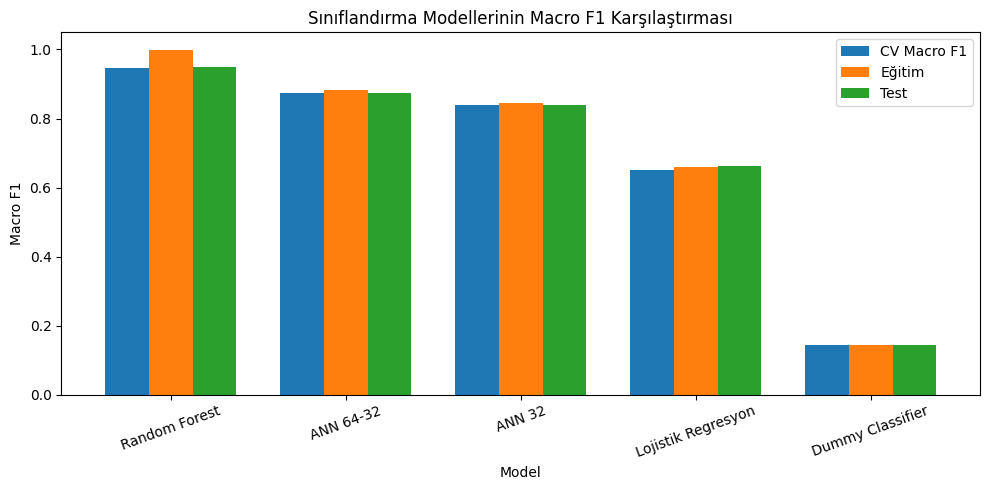

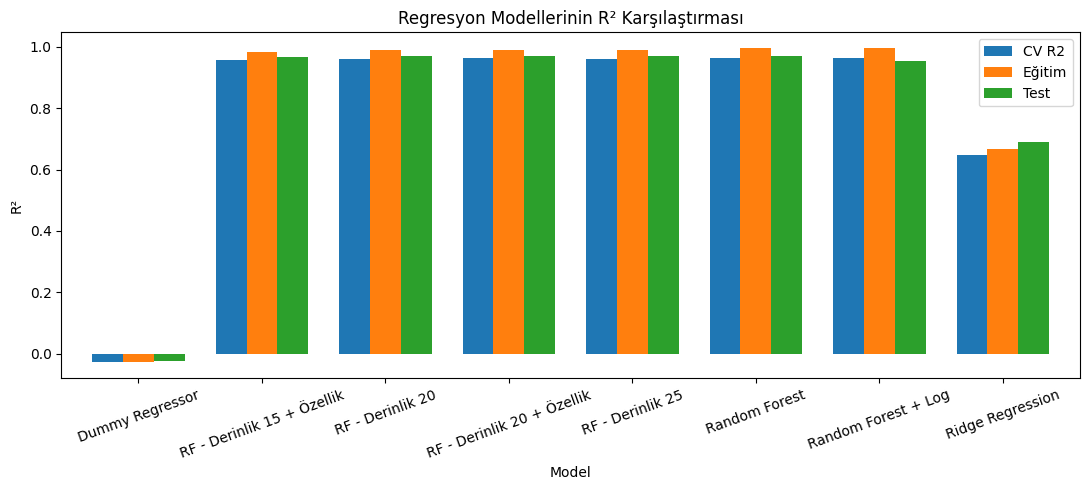

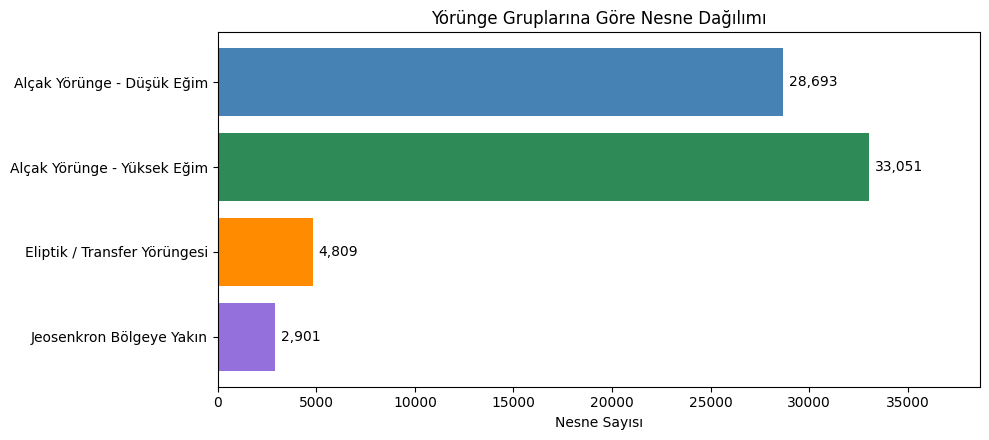

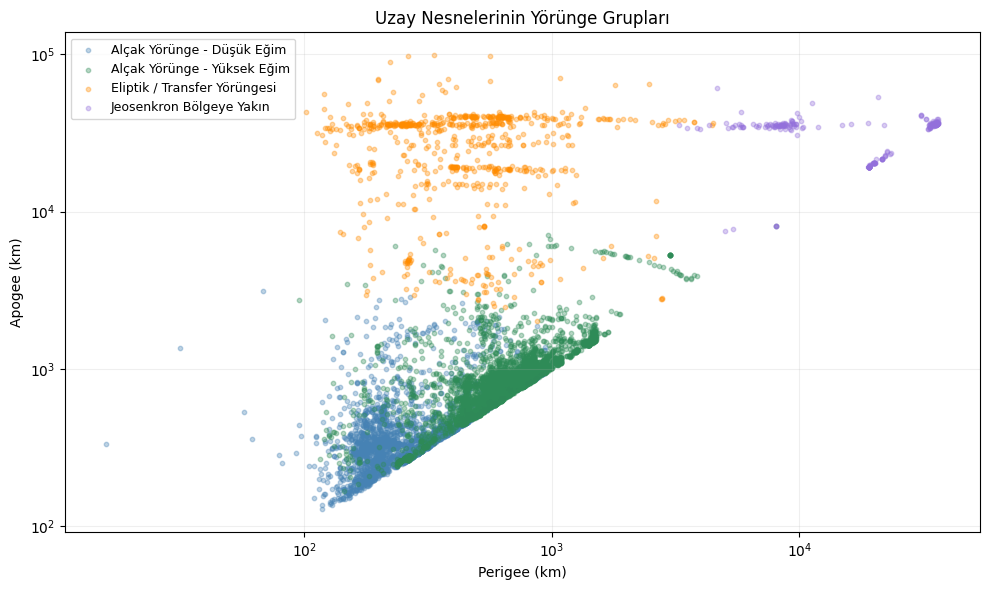

Grafikler kaydedildi: /content/drive/MyDrive/outputs


In [93]:
ax = sinif_ozet[["CV Macro F1", "Eğitim", "Test"]].plot(
    kind="bar", figsize=(10, 5), width=0.75
)
ax.set_title("Sınıflandırma Modellerinin Macro F1 Karşılaştırması")
ax.set_ylabel("Macro F1")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(sonuc_klasoru / "siniflandirma_karsilastirma.png", dpi=200, bbox_inches="tight")
plt.show()

reg_r2 = regresyon_sonuc.pivot(
    index="Model", columns="Bölüm", values="R2"
).join(regression_cv_results.set_index("Model")[["CV R2"]])

ax = reg_r2[["CV R2", "Eğitim", "Test"]].plot(
    kind="bar", figsize=(11, 5), width=0.75
)
ax.set_title("Regresyon Modellerinin R² Karşılaştırması")
ax.set_ylabel("R²")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(sonuc_klasoru / "regresyon_karsilastirma.png", dpi=200, bbox_inches="tight")
plt.show()

sirali_gruplar = list(renkler.keys())
sayilar = cluster_sonuc["Yörünge Grubu"].value_counts().reindex(sirali_gruplar)

plt.figure(figsize=(10, 4.5))
plt.barh(sirali_gruplar, sayilar, color=[renkler[g] for g in sirali_gruplar])
plt.gca().invert_yaxis()
plt.xlabel("Nesne Sayısı")
plt.title("Yörünge Gruplarına Göre Nesne Dağılımı")

for i, sayi in enumerate(sayilar):
    plt.text(sayi + 300, i, f"{sayi:,}", va="center")

plt.xlim(0, sayilar.max() * 1.17)
plt.tight_layout()
plt.savefig(sonuc_klasoru / "kume_dagilimi.png", dpi=200, bbox_inches="tight")
plt.show()

ornek = cluster_sonuc.sample(n=min(10000, len(cluster_sonuc)), random_state=SEED)

plt.figure(figsize=(10, 6))

for grup in sirali_gruplar:
    veri = ornek[ornek["Yörünge Grubu"] == grup]
    plt.scatter(
        veri["Perigee"], veri["Apogee"],
        s=10, alpha=0.35, color=renkler[grup], label=grup
    )

plt.xscale("symlog", linthresh=100)
plt.yscale("symlog", linthresh=100)
plt.xlabel("Perigee (km)")
plt.ylabel("Apogee (km)")
plt.title("Uzay Nesnelerinin Yörünge Grupları")
plt.legend(fontsize=9)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(sonuc_klasoru / "yörünge_kumeleri.png", dpi=200, bbox_inches="tight")
plt.savefig(sonuc_klasoru / "grafik_adi.png", dpi=200, bbox_inches="tight")
plt.show()

print("Grafikler kaydedildi:", sonuc_klasoru)

## Kaynaklar

- McDowell, J. C. [General Catalog of Artificial Space Objects (GCAT)](https://planet4589.org/space/gcat/). Veri kaynağı: Standard Satellite Catalog (`satcat.tsv`). Erişim tarihi: 09.11.2026.
- Scikit-learn. [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
- Scikit-learn. [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html).
- Scikit-learn. [Clustering](https://scikit-learn.org/stable/modules/clustering.html).